# Beyond Calendar Features: Physics-Constrained LSTM Forecasting of Flood Stage on the Shannon Callows

## Introduction
This notebook implements the analysis for a physics-informed machine learning (PIML) study
of flood stage forecasting at OPW Station 25017, Banagher Bridge, River Shannon. The
operational problem is real-time flood warning for a property adjacent to the river at
Banagher, Co. Offaly, where the current alert system uses a deterministic rolling-slope
estimator over a 75-minute window. That estimator is reactive and locally linear; it
cannot anticipate a flood wave arriving from upstream or capture the non-linear storage
dynamics of the Shannon callows floodplain.

An earlier attempt using XGBoost regression on calendar features (hour, dayofweek, month,
year, dayofyear) produced a train RMSE of 0.085 m against a test RMSE of 0.638 m,
confirming that date features alone provide no meaningful event signal — they encode
seasonal prior probability, not actual flood state. The dominant feature by importance was
year, indicating the model exploited mean-level differences between training and test
periods rather than learning transferable flood dynamics.

This work replaces that approach with a physics-constrained LSTM trained using a composite
loss function that penalises solutions violating established hydraulic laws: Manning's
stage-discharge relationship, exponential recession dynamics, and an empirically-derived
rise rate bound. The core comparison is Experiment 1C (LSTM, data-only loss) versus
Experiment 1D (LSTM, composite physics loss) — identical architecture, different loss
function. This isolates the contribution of the physics constraints.



## Methodology
### Data
**Source:** Office of Public Works (OPW), National Hydrometric Monitoring Network,
waterlevel.ie. Data downloaded as CSV export from the station portal.

**Primary dataset:** Station 25017 (Banagher Bridge) 15-minute autographic water level
record. 1,218,710 readings spanning **1989-01-02 to 2024-03-14** (approximately 35 years).
Datum correction applied at load time: all values expressed as metres above local gauge
datum (raw value − 30.330 m, where 30.330 mOD is the gauge datum above Ordnance Datum
Malin Head, OSGM15).

**Supporting dataset:** Station 25017 daily summary (Day Min, Day Mean, Day Max).
12,855 rows, same date range. Used for exploratory analysis and outlier removal.

**Temporal split (no random shuffling):**
- Training: 1989–2010
- Validation: 2011–2017
- Test: 2018–2024-03-14 (held out; includes 2015–16 and 2023–24 flood seasons)



### Assumptions and Fixed Parameters

The following constants are fixed for all experiments in this notebook. Where a value
is derived from the OPW/Jacobs CFRAM Level Operation Review (TD_HYDR_0114_V2_A, 2012),
the source is noted. Parameters marked *uncalibrated* require field measurement or an
OPW rating curve request to confirm; they are treated as first-order estimates.

| Parameter | Symbol | Value | Source / Basis |
|---|---|---|---|
| Flood threshold | `THRESHOLD` | 2.6952 m | Field observation: 1 ft water in adjacent field at gauge reading of 3 m (April 2024); 3 − 0.3048 = 2.6952 m local gauge datum |
| Warning margin | `WARN_MARGIN` | 0.20 m | Operational — alert triggered at THRESHOLD − 0.20 m |
| Gauge datum | `GAUGE_DATUM` | 30.330 mOD | OPW metadata, Station 25017; Malin Head datum (OSGM15) |
| Channel width at bridge | `W` | 160 m | Direct observation, Banagher Bridge; representative of main channel reach (varies 100–180 m upriver) |
| Bed slope (callows reach) | `S₀` | 2×10⁻⁵ | Read from CFRAM Figure 1.2 longitudinal section, Athlone–Meelick reach |
| Manning's roughness | `N_MANNING` | 0.033 | *Uncalibrated* — typical for large lowland sand-bed river; pending calibration against OPW rating curve (Phase 3) |
| Timestep | `DT_MIN` | 15 min | Fixed by OPW autographic sensor cadence |
| Input window | `W_SEQ` | 96 steps (24 h) | Captures full diurnal cycle and recent trend |
| Forecast horizons | `HORIZONS` | 1h, 6h, 12h, 24h, 48h | Operationally relevant; 48h is the outer limit of meaningful single-station forecasting |


### 1. Import Libraries and Declare initial variables

In [22]:
import time, os, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import curve_fit
from scipy.signal import find_peaks

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import StandardScaler

import warnings

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
# ── Gauge / datum ─────────────────────────────────────────────────────────────
GAUGE_DATUM   = 30.330        # Station 25017 gauge datum, mOD Malin Head (OSGM15)

# ── Operational thresholds ────────────────────────────────────────────────────
THRESHOLD     = 3 - 0.3048    # 2.6952 m — field observation: 1 ft water in field at 3 m mark
WARN_MARGIN   = 0.20          # warning triggered at THRESHOLD − WARN_MARGIN

# ── CFRAM hydraulic parameters (TD_HYDR_0114, Jacobs/OPW 2012) ───────────────
W             = 160.0         # channel width at Banagher Bridge, m
S0            = 2e-5          # bed slope, callows reach (1 in 50,000)
N_MANNING     = 0.033         # Manning's n, main channel (uncalibrated)
DT_MIN        = 15            # timestep, minutes

print(f"Threshold: {THRESHOLD:.4f} m  |  Warning: {THRESHOLD - WARN_MARGIN:.4f} m")
print(f"Manning Q at threshold: {(W/N_MANNING) * THRESHOLD**(5/3) * S0**0.5:.1f} m³/s")

Threshold: 2.6952 m  |  Warning: 2.4952 m
Manning Q at threshold: 113.2 m³/s


### 1b: Import Datasets

In [3]:
# Update these paths if the CSVs are not in the same directory as the notebook
PATH_15MIN = 'tsvalues.csv'
PATH_DAILY = '25017_banagher_s_complete.csv'

# ── 15-minute level record ────────────────────────────────────────────────────
df = pd.read_csv(PATH_15MIN, sep=';', skiprows=10).iloc[:, :-1]
df = df.rename(columns={'#Timestamp': 'Timestamp'}).set_index('Timestamp')
df.index = pd.to_datetime(df.index, format='mixed', dayfirst=True)
df['Value'] = df['Value'] - GAUGE_DATUM

# ── Daily summary record ──────────────────────────────────────────────────────
df_daily = pd.read_csv(PATH_DAILY, skiprows=12).iloc[:, :-1]
df_daily = df_daily.set_index('Day')
df_daily.index = pd.to_datetime(df_daily.index, format='mixed', dayfirst=True)
for col in ['Day Min', 'Day Mean', 'Day Max']:
    df_daily[col] = df_daily[col] - GAUGE_DATUM

print(f"15-min record:  {len(df):,} rows  |  {df.index[0].date()} → {df.index[-1].date()}")
print(f"Daily record:   {len(df_daily):,} rows  |  {df_daily.index[0].date()} → {df_daily.index[-1].date()}")
print(f"\nLevel range (15-min): {df['Value'].min():.3f} m  →  {df['Value'].max():.3f} m")

15-min record:  1,218,710 rows  |  1989-01-02 → 2024-03-14
Daily record:   12,855 rows  |  1989-01-02 → 2024-03-13

Level range (15-min): 1.930 m  →  4.446 m


### 2. Initial EDA

In [4]:
# Manning's discharge proxy at each timestep (wide-channel approximation)
df['Q_manning'] = (W / N_MANNING) * (df['Value'].clip(lower=0.01) ** (5/3)) * (S0 ** 0.5)

# Rise rate dh/dt [m/hr] — forward difference
df['dh_dt'] = df['Value'].diff() / (DT_MIN / 60.0)

# Flood flag and event onset
df['in_flood']    = (df['Value'] >= THRESHOLD).astype(int)
df['event_start'] = (df['in_flood'] == 1) & (df['in_flood'].shift(1) == 0)

# Summary statistics
n_events    = df['event_start'].sum()
flood_frac  = df['in_flood'].mean()
p95_rise    = df.loc[df['dh_dt'] > 0, 'dh_dt'].quantile(0.95)
p99_rise    = df.loc[df['dh_dt'] > 0, 'dh_dt'].quantile(0.99)

print(f"Flood events (crossings of {THRESHOLD:.4f} m): {n_events}")
print(f"Flood fraction of full record:               {flood_frac*100:.1f}%")
print(f"Manning Q at threshold:                      {(W/N_MANNING)*THRESHOLD**(5/3)*S0**0.5:.1f} m³/s")
print(f"\nP95 rise rate: {p95_rise:.4f} m/hr")
print(f"P99 rise rate: {p99_rise:.4f} m/hr")

Flood events (crossings of 2.6952 m): 194
Flood fraction of full record:               33.8%
Manning Q at threshold:                      113.2 m³/s

P95 rise rate: 0.0120 m/hr
P99 rise rate: 0.0200 m/hr


In [5]:
# ── Identify peaks above threshold ───────────────────────────────────────────
# Work on daily means for cleaner peak detection (less 15-min noise)
daily_mean = df['Value'].resample('D').mean().dropna()

peaks_idx, _ = find_peaks(
    daily_mean.values,
    height=THRESHOLD,
    distance=10
)

peak_dates  = daily_mean.index[peaks_idx]
peak_levels = daily_mean.values[peaks_idx]
print(f"Peaks found above threshold: {len(peaks_idx)}")

def recession_model(t, h_base, K_r):
    return h_base + (h_peak - h_base) * np.exp(-t / K_r)

K_r_estimates = []

for pk_date, h_peak in zip(peak_dates, peak_levels):
    end_date = pk_date + pd.Timedelta(days=60)
    limb = daily_mean[pk_date:end_date]

    if len(limb) < 10:
        continue

    t = np.arange(len(limb), dtype=float)
    h = limb.values

    # bounds relative to this limb — h_base must be below the peak
    h_base_lo   = max(0.0, h.min() * 0.8)
    h_base_hi   = h_peak * 0.99
    h_base_init = np.clip(h.min(), h_base_lo + 0.01, h_base_hi - 0.01)

    try:
        popt, _ = curve_fit(
            recession_model, t, h,
            p0=[h_base_init, 15.0],
            bounds=([h_base_lo, 1.0], [h_base_hi, 120.0]),
            maxfev=5000
        )
        h_base_fit, K_r_fit = popt
        if 3 < K_r_fit < 90:
            K_r_estimates.append(K_r_fit)
    except (RuntimeError, ValueError):
        pass

K_r_estimates = np.array(K_r_estimates)

print(f"\nSuccessful recession fits: {len(K_r_estimates)} of {len(peaks_idx)} peaks")
print(f"K_r  median : {np.median(K_r_estimates):.1f} days")
print(f"K_r  mean   : {np.mean(K_r_estimates):.1f} days")
print(f"K_r  P25–P75: {np.percentile(K_r_estimates, 25):.1f} – {np.percentile(K_r_estimates, 75):.1f} days")
print(f"K_r  range  : {K_r_estimates.min():.1f} – {K_r_estimates.max():.1f} days")


Peaks found above threshold: 260

Successful recession fits: 159 of 260 peaks
K_r  median : 20.1 days
K_r  mean   : 28.4 days
K_r  P25–P75: 9.4 – 44.8 days
K_r  range  : 3.0 – 89.3 days


### Flood event visualisation with recession curves

Figure caption — Station 25017 flood event case studies with exponential recession fit

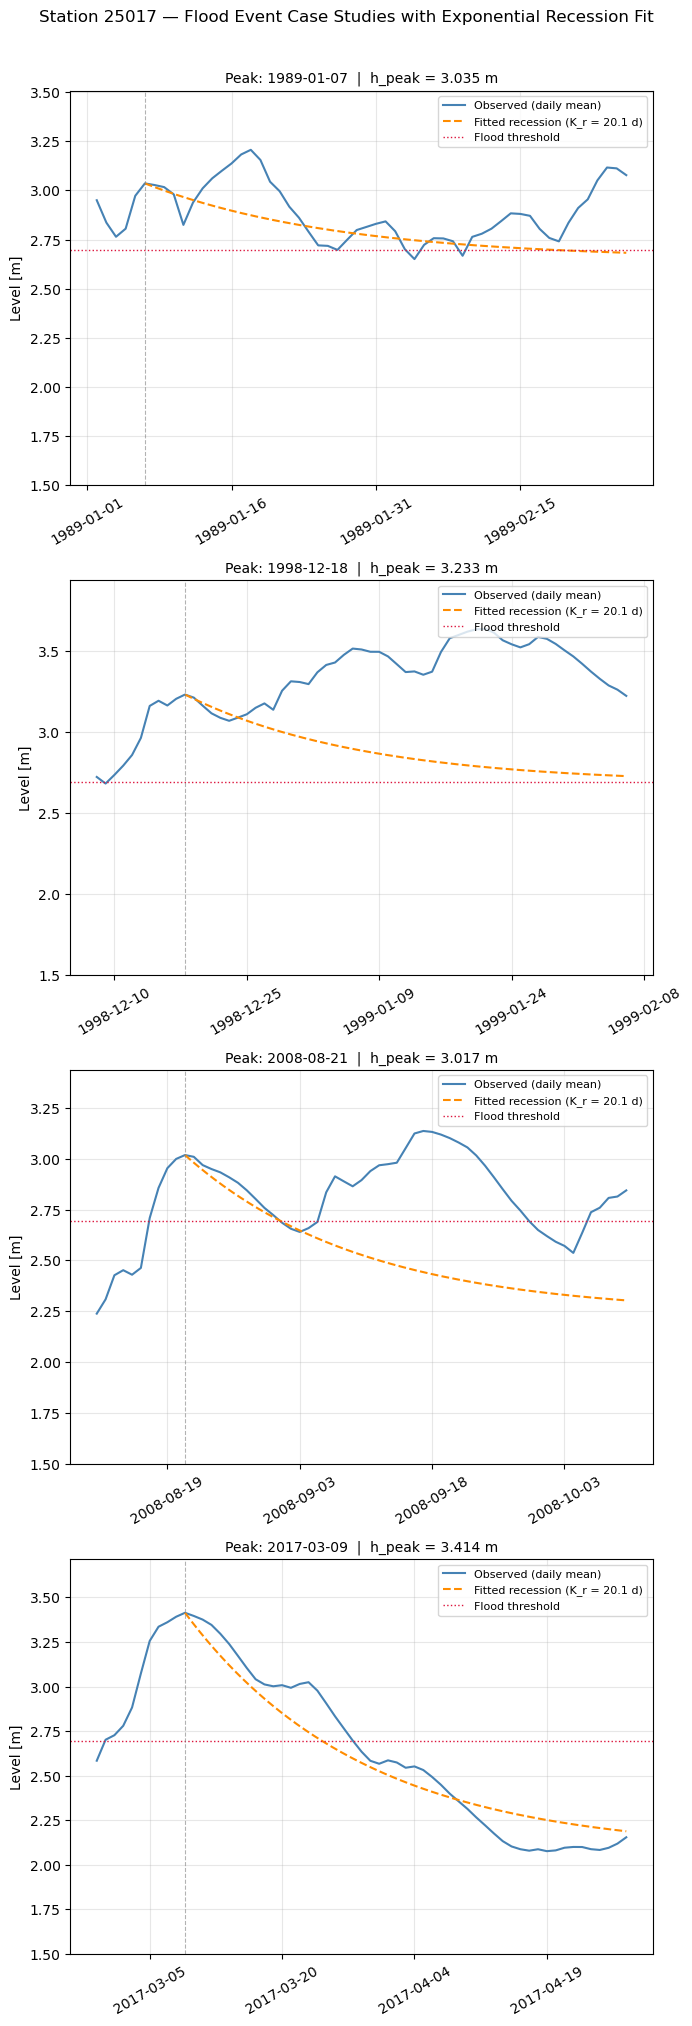

K_r used: 20.1 days (median of 159 fitted events)


In [6]:
K_r_USE = np.median(K_r_estimates)   # 20.1 days — confirmed

# Select 4 events spread across the record for case study plots
# Pick manually from the peak list or let the code sample evenly
n_plots  = 4
step     = len(peak_dates) // n_plots
selected = [(peak_dates[i * step], peak_levels[i * step]) for i in range(n_plots)]

fig, axes = plt.subplots(n_plots, 1, figsize=(7, 5 * n_plots), sharex=False)

for ax, (pk_date, h_peak) in zip(axes, selected):
    # Observed level: 60 days around the peak (10 days before, 50 after)
    start = pk_date - pd.Timedelta(days=10)
    end   = pk_date + pd.Timedelta(days=50)
    obs   = daily_mean[start:end]

    # Fitted recession curve from peak onward
    t_fit   = np.linspace(0, 50, 300)
    h_base  = obs.min()
    h_curve = h_base + (h_peak - h_base) * np.exp(-t_fit / K_r_USE)
    dates_fit = pk_date + pd.to_timedelta(t_fit, unit='D')

    ax.plot(obs.index, obs.values, color='steelblue', lw=1.5, label='Observed (daily mean)')
    ax.plot(dates_fit, h_curve, color='darkorange', lw=1.5, ls='--',
            label=f'Fitted recession (K_r = {K_r_USE:.1f} d)')
    ax.axhline(THRESHOLD, color='crimson', lw=1, ls=':', label='Flood threshold')
    ax.axvline(pk_date, color='grey', lw=0.8, ls='--', alpha=0.6)

    ax.set_title(f'Peak: {pk_date.date()}  |  h_peak = {h_peak:.3f} m', fontsize=10)
    ax.set_ylabel('Level [m]')
    ax.legend(fontsize=8, loc='upper right')
    ax.set_ylim(1.5, obs.max() + 0.3)
    ax.grid(True, alpha=0.3)
    ax.xaxis.set_major_locator(plt.MaxNLocator(6))
    ax.tick_params(axis='x', rotation=30)   

plt.suptitle('Station 25017 — Flood Event Case Studies with Exponential Recession Fit', y=1.01)

plt.rcParams.update({
    'font.size': 9,
    'axes.titlesize': 9,
    'axes.labelsize': 8,
    'legend.fontsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
})

for i, (ax, (pk_date, h_peak)) in enumerate(zip(axes, selected)):
    extent = ax.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
    # expand slightly to include title and labels
    fig.savefig(f'recession_event_{pk_date.date()}.pdf',
                bbox_inches=extent.expanded(1.15, 1.25))

    
plt.tight_layout()

# For a journal — PDF is vector (scales perfectly, preferred by most journals)
plt.savefig('recession_case_studies.pdf', bbox_inches='tight')

# Or PNG at 300 DPI (minimum for print)
plt.savefig('recession_case_studies.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"K_r used: {K_r_USE:.1f} days (median of {len(K_r_estimates)} fitted events)")

The orange dashed curve represents the median exponential recession (K_r = 20.1 days) fitted from the peak of each event. The blue line is the observed daily mean level. The dotted red line marks the flood threshold (2.6952 m).

* Panel 1 — January 1989. Observed recession initially tracks the fitted curve before a secondary rise interrupts drainage. The event does not complete a clean single recession.

* Panel 2 — December 1998. Observed level remains persistently above the fitted curve through January 1999, indicating a recession rate substantially slower than the median. Consistent with a saturated winter catchment and sustained groundwater drainage.

* Panel 3 — August 2008. Initial recession broadly consistent with the fitted curve. A second independent event begins before the river returns to baseflow, interrupting the recession and returning the level above threshold in September.

* Panel 4 — March 2017. Observed recession is steeper than the fitted curve, indicating faster-than-median drainage. The event completes cleanly with no secondary interruption.

### Feature engineering and sliding window sequences

In [7]:

# ── Temporal train / val / test split ────────────────────────────────────────
train = df.loc[df.index < '2011-01-01'].copy()
val   = df.loc[(df.index >= '2011-01-01') & (df.index < '2018-01-01')].copy()
test  = df.loc[df.index >= '2018-01-01'].copy()

print(f"Train: {len(train):,} rows  ({train.index[0].date()} → {train.index[-1].date()})")
print(f"Val:   {len(val):,} rows  ({val.index[0].date()} → {val.index[-1].date()})")
print(f"Test:  {len(test):,} rows  ({test.index[0].date()} → {test.index[-1].date()})")

# ── Feature engineering ───────────────────────────────────────────────────────
def add_features(df):
    out = df[['Value', 'dh_dt', 'Q_manning']].copy()

    # Cyclical time encodings
    doy = df.index.day_of_year
    hod = df.index.hour + df.index.minute / 60
    out['sin_doy'] = np.sin(2 * np.pi * doy / 365)
    out['cos_doy'] = np.cos(2 * np.pi * doy / 365)
    out['sin_hod'] = np.sin(2 * np.pi * hod / 24)
    out['cos_hod'] = np.cos(2 * np.pi * hod / 24)

    # Cumulative rise over past 72 hours — rainfall proxy
    out['cum_rise_72h'] = (
        df['dh_dt'].clip(lower=0)
        .rolling(window=72 * 4, min_periods=1)
        .sum() * (DT_MIN / 60)
    )

    return out.dropna()

train_f = add_features(train)
val_f   = add_features(val)
test_f  = add_features(test)

FEATURES = ['Value', 'dh_dt', 'Q_manning',
            'sin_doy', 'cos_doy', 'sin_hod', 'cos_hod', 'cum_rise_72h']
TARGET    = 'Value'

# ── Normalise (fit scaler on train only) ──────────────────────────────────────
scaler = StandardScaler()
train_f[FEATURES] = scaler.fit_transform(train_f[FEATURES])
val_f[FEATURES]   = scaler.transform(val_f[FEATURES])
test_f[FEATURES]  = scaler.transform(test_f[FEATURES])

# Store target scaler separately — needed to invert predictions back to metres
target_mean = scaler.mean_[0]
target_std  = scaler.scale_[0]

print(f"\nFeatures: {FEATURES}")
print(f"Target normalisation — mean: {target_mean:.4f} m  std: {target_std:.4f} m")

# ── Sliding window sequence builder ──────────────────────────────────────────
W_SEQ     = 96          # input window: 24 h at 15-min resolution
HORIZONS  = [4, 24, 48, 96, 192]   # steps ahead → [1h, 6h, 12h, 24h, 48h]

def make_sequences(df_feat, w=W_SEQ, horizons=HORIZONS):
    X, Y = [], []
    vals = df_feat[FEATURES].values
    tgt  = df_feat[TARGET].values

    for i in range(w, len(vals) - max(horizons)):
        X.append(vals[i - w : i])
        Y.append([tgt[i + h] for h in horizons])

    return np.array(X, dtype=np.float32), np.array(Y, dtype=np.float32)

X_train, Y_train = make_sequences(train_f)
X_val,   Y_val   = make_sequences(val_f)
X_test,  Y_test  = make_sequences(test_f)

print(f"\nX_train: {X_train.shape}  →  (sequences, timesteps, features)")
print(f"Y_train: {Y_train.shape}  →  (sequences, horizons)")
print(f"X_val:   {X_val.shape}")
print(f"X_test:  {X_test.shape}")

Train: 760,634 rows  (1989-01-02 → 2010-12-31)
Val:   240,834 rows  (2011-01-01 → 2017-12-31)
Test:  217,242 rows  (2018-01-01 → 2024-03-14)

Features: ['Value', 'dh_dt', 'Q_manning', 'sin_doy', 'cos_doy', 'sin_hod', 'cos_hod', 'cum_rise_72h']
Target normalisation — mean: 2.5090 m  std: 0.4974 m

X_train: (760345, 96, 8)  →  (sequences, timesteps, features)
Y_train: (760345, 5)  →  (sequences, horizons)
X_val:   (240546, 96, 8)
X_test:  (216954, 96, 8)


### Define the Model

In [15]:

DEVICE = torch.device('mps' if torch.backends.mps.is_available()
                       else 'cuda' if torch.cuda.is_available()
                       else 'cpu')
print(f"Device: {DEVICE}")

# ── Convert to tensors ────────────────────────────────────────────────────────
def to_tensors(X, Y):
    return (torch.tensor(X, dtype=torch.float32),
            torch.tensor(Y, dtype=torch.float32))

Xt_train, Yt_train = to_tensors(X_train, Y_train)
Xt_val,   Yt_val   = to_tensors(X_val,   Y_val)
Xt_test,  Yt_test  = to_tensors(X_test,  Y_test)

train_loader = DataLoader(TensorDataset(Xt_train, Yt_train),
                          batch_size=256, shuffle=True,  num_workers=0)
val_loader   = DataLoader(TensorDataset(Xt_val,   Yt_val),
                          batch_size=256, shuffle=False, num_workers=0)

# ── Model ─────────────────────────────────────────────────────────────────────
class FloodLSTM(nn.Module):
    def __init__(self, n_features=8, hidden=128, n_layers=2,
                 dropout=0.2, n_horizons=5):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_features,
                            hidden_size=hidden,
                            num_layers=n_layers,
                            dropout=dropout,
                            batch_first=True)
        self.fc   = nn.Sequential(
            nn.Linear(hidden, 64),
            nn.ReLU(),
            nn.Linear(64, n_horizons)
        )

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)   # h_n: (n_layers, batch, hidden)
        out = self.fc(h_n[-1])        # take last layer's hidden state
        return out

model = FloodLSTM().to(DEVICE)
print(model)
print(f"\nTrainable parameters: {sum(p.numel() for p in model.parameters()):,}")

Device: mps
FloodLSTM(
  (lstm): LSTM(8, 128, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=5, bias=True)
  )
)

Trainable parameters: 211,333


In [16]:
# Cell 8 — Experiment 1C: data-only LSTM (30 epochs, full run)

EPOCHS    = 15  #reduced from 30
LR        = 1e-3
THRESHOLD_NORM = (THRESHOLD - target_mean) / target_std  # flood threshold in normalised space

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)
criterion = nn.MSELoss()

history = {'train_loss': [], 'val_loss': []}
best_val = float('inf')

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()

    # ── Train ────────────────────────────────────────────────────────────────
    model.train()
    train_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        pred = model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        train_loss += loss.item() * len(xb)

    train_loss /= len(Xt_train)

    # ── Validate ─────────────────────────────────────────────────────────────
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            pred = model(xb)
            val_loss += criterion(pred, yb).item() * len(xb)

    val_loss /= len(Xt_val)
    scheduler.step(val_loss)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)

    if val_loss < best_val:
        best_val = val_loss
        best_epoch = epoch          # ← add this line
        torch.save(model.state_dict(), 'lstm_1c_best.pt')

    print(f"Epoch {epoch:02d}/{EPOCHS}  "
          f"train: {train_loss:.6f}  val: {val_loss:.6f}  "
          f"time: {time.time()-t0:.1f}s")

print(f"\nBest val loss: {best_val:.6f}")

Epoch 01/15  train: 0.011364  val: 0.008625  time: 348.7s
Epoch 02/15  train: 0.005573  val: 0.006134  time: 322.7s
Epoch 03/15  train: 0.005225  val: 0.005737  time: 311.5s
Epoch 04/15  train: 0.004783  val: 0.006963  time: 314.6s
Epoch 05/15  train: 0.004291  val: 0.008668  time: 283.9s
Epoch 06/15  train: 0.003746  val: 0.008884  time: 331.0s
Epoch 07/15  train: 0.003261  val: 0.009396  time: 332.8s
Epoch 08/15  train: 0.002553  val: 0.009558  time: 305.5s
Epoch 09/15  train: 0.002277  val: 0.010375  time: 304.4s
Epoch 10/15  train: 0.002049  val: 0.010499  time: 306.9s
Epoch 11/15  train: 0.001915  val: 0.010754  time: 314.4s
Epoch 12/15  train: 0.001578  val: 0.011438  time: 317.8s
Epoch 13/15  train: 0.001432  val: 0.010992  time: 300.4s
Epoch 14/15  train: 0.001340  val: 0.010983  time: 320.1s
Epoch 15/15  train: 0.001314  val: 0.011091  time: 331.2s

Best val loss: 0.005737


### 

In [ ]:
# Cell 8 — Experiment 1C: data-only LSTM
# ── Commented out: run on fresh start only ────────────────────────────────────
# FRESH RUN ONLY — change `if False:` to `if True:` to retrain. Saves lstm_1c_best.pt + lstm_1c_history.json.
if False:
    import os, json

    CKPT_1C = 'lstm_1c_best.pt'
    HIST_1C = 'lstm_1c_history.json'

    model = FloodLSTM().to(DEVICE)

    EPOCHS = 15
    LR     = 1e-3

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)
    criterion = nn.MSELoss()

    history    = {'train_loss': [], 'val_loss': []}
    best_val   = float('inf')
    best_epoch = 0

    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()

        model.train()
        train_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            train_loss += loss.item() * len(xb)
        train_loss /= len(Xt_train)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                val_loss += criterion(model(xb), yb).item() * len(xb)
        val_loss /= len(Xt_val)
        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        if val_loss < best_val:
            best_val, best_epoch = val_loss, epoch
            torch.save(model.state_dict(), CKPT_1C)
            flag = '  ← BEST'
        else:
            flag = ''

        print(f"Epoch {epoch:02d}/{EPOCHS}  "
              f"train: {train_loss:.6f}  val: {val_loss:.6f}  "
              f"time: {time.time()-t0:.1f}s{flag}")

    with open(HIST_1C, 'w') as f:
        json.dump({'history': history,
                   'best_val': best_val,
                   'best_epoch': best_epoch}, f)
    print(f"\nBest val MSE: {best_val:.6f} at epoch {best_epoch}")

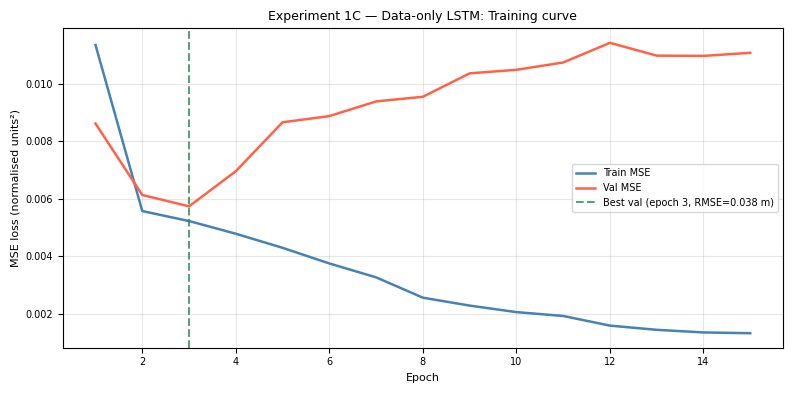

In [17]:
# Cell 9a — Experiment 1C learning curve

epochs     = list(range(1, len(history['train_loss']) + 1))
best_rmse  = np.sqrt(best_val) * target_std

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(epochs, history['train_loss'], label='Train MSE', color='steelblue', linewidth=1.8)
ax.plot(epochs, history['val_loss'],   label='Val MSE',   color='tomato',    linewidth=1.8)
ax.axvline(x=best_epoch, linestyle='--', color='seagreen', alpha=0.8,
           label=f'Best val (epoch {best_epoch}, RMSE={best_rmse:.3f} m)')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE loss (normalised units²)')
ax.set_title('Experiment 1C — Data-only LSTM: Training curve')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('1c_learning_curve.pdf', bbox_inches='tight')
plt.savefig('1c_learning_curve.png', dpi=300, bbox_inches='tight')
plt.show()

### Experiment 1C: test-set evaluation

In [19]:
# Cell 9b-setup — test DataLoader

Xt_test  = torch.tensor(X_test)
Yt_test  = torch.tensor(Y_test)
test_ds  = TensorDataset(Xt_test, Yt_test)
test_loader = DataLoader(test_ds, batch_size=512, shuffle=False)

In [20]:
# Cell 9b — Experiment 1C: test-set evaluation

model.load_state_dict(torch.load('lstm_1c_best.pt', map_location=DEVICE))
model.eval()

preds, actuals = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(DEVICE)
        preds.append(model(xb).cpu().numpy())
        actuals.append(yb.numpy())

preds   = np.concatenate(preds)   * target_std + target_mean
actuals = np.concatenate(actuals) * target_std + target_mean

horizon_labels = ['T+1h', 'T+6h', 'T+12h', 'T+24h', 'T+48h']

print(f"{'Horizon':<10} {'RMSE (m)':>10} {'NSE':>10}")
print("-" * 32)
for i, lbl in enumerate(horizon_labels):
    rmse = np.sqrt(np.mean((preds[:, i] - actuals[:, i]) ** 2))
    ss_res = np.sum((preds[:, i] - actuals[:, i]) ** 2)
    ss_tot = np.sum((actuals[:, i] - actuals[:, i].mean()) ** 2)
    nse  = 1 - ss_res / ss_tot
    print(f"{lbl:<10} {rmse:>10.4f} {nse:>10.4f}")

# Physics violation rate — predicted rise rate exceeds P95
P95_RISE = 0.0120  # m/hr, empirically confirmed from 35-year record
dt_hr    = 0.25    # 15-min timestep in hours
pred_dh  = np.diff(preds, axis=0) / dt_hr
viol_rate = np.mean(np.abs(pred_dh) > P95_RISE)
print(f"\nPhysics violation rate (|dh/dt| > {P95_RISE} m/hr): {viol_rate:.4f}")

Horizon      RMSE (m)        NSE
--------------------------------
T+1h           0.0098     0.9997
T+6h           0.0126     0.9995
T+12h          0.0179     0.9989
T+24h          0.0328     0.9964
T+48h          0.0649     0.9858

Physics violation rate (|dh/dt| > 0.012 m/hr): 0.3303


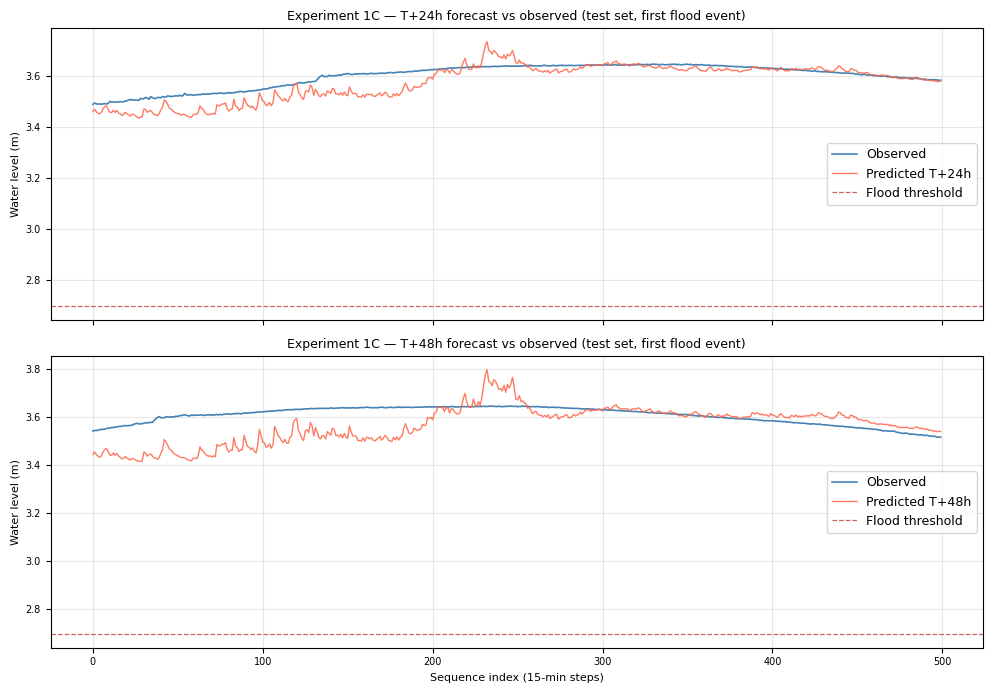

In [21]:
# Cell 9c — Predicted vs observed: flood event on test set (T+24h and T+48h)

# Rebuild test predictions from the loaded model (already done in 9b)
# preds and actuals are (N, 5) arrays in metres — reuse from Cell 9b

# Find a flood event in the test set: locate sequences where observed peak > THRESHOLD
peak_obs = actuals[:, 3]  # T+24h observed column
flood_idx = np.where(peak_obs > THRESHOLD)[0]

# Take the first sustained flood window (at least 200 consecutive points)
start = flood_idx[0]
end   = min(start + 500, len(actuals))

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

for ax, h_idx, lbl in zip(axes, [3, 4], ['T+24h', 'T+48h']):
    ax.plot(actuals[start:end, h_idx], color='steelblue',
            linewidth=1.2, label='Observed')
    ax.plot(preds[start:end, h_idx],   color='tomato',
            linewidth=1.0, label=f'Predicted {lbl}', alpha=0.85)
    ax.axhline(THRESHOLD, linestyle='--', color='firebrick',
               linewidth=0.9, alpha=0.7, label='Flood threshold')
    ax.set_ylabel('Water level (m)')
    ax.set_title(f'Experiment 1C — {lbl} forecast vs observed (test set, first flood event)')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Sequence index (15-min steps)')
plt.tight_layout()
plt.savefig('1c_forecast_flood.pdf', bbox_inches='tight')
plt.savefig('1c_forecast_flood.png', dpi=300, bbox_inches='tight')
plt.show()

### Experiment 1D: Phase 1 PIML-LSTM (L_data + L_bounds + L_recession)

Here the LSTM has physical bounds set, transforming it into a PIML-LSTM or a PINN, a physics informed Neural Network.

**Architecture:** identical to Experiment 1C (`FloodLSTM`)
- 2 LSTM layers, hidden size 128, dropout 0.2
- 5 output heads (T+1h, T+6h, T+12h, T+24h, T+48h)
- 211,333 trainable parameters
- Initialised from Experiment 1C best checkpoint (epoch 3)

**What changes:** loss function only — not the network architecture.

| Experiment | Loss function |
|---|---|
| 1C | L = L_data |
| 1D | L = L_data + 0.1 · L_bounds + 0.05 · L_recession |

**L_bounds:** penalises predicted rate-of-change between adjacent forecast horizons exceeding the empirical P95 rise rate (0.012 m/hr), converted to normalised units.

**L_recession:** during confirmed recession windows (level above flood threshold and falling over the preceding hour), penalises positive increments across forecast horizons.

**Key distinction for paper:** a PINN is a standard network trained with a physics-informed loss function. The physics is encoded in the training signal, not the architecture. The 1C vs 1D comparison is therefore a controlled experiment — same capacity, same initialisation, different objective.

**Expected effect:** weights settle into a region of parameter space that trades a small reduction in data fit for a large reduction in physically implausible predictions. Physics violation rate expected to fall substantially from the 1C baseline of 33.0%.

* We want to compare the results, see if the physics rules added smoothed the curve, gave better results etc

In [ ]:
# Cell 10 — Experiment 1D: Phase 1 PIML-LSTM (L_data + L_bounds + L_recession)
# Loads from lstm_1d_best.pt + lstm_1d_history.json if they exist. Delete both files to retrain.
CKPT_1D = 'lstm_1d_best.pt'
HIST_1D = 'lstm_1d_history.json'

# ── Physics constants (derived — no hardcoding) ───────────────────────────────
P95_NORM       = p95_rise / target_std
THRESHOLD_NORM = (THRESHOLD - target_mean) / target_std
HORIZON_HRS    = [h * DT_MIN / 60 for h in HORIZONS]
DT_HRS         = [h2 - h1 for h1, h2 in zip(HORIZON_HRS[:-1], HORIZON_HRS[1:])]
steps_per_hour = int(60 / DT_MIN)

# ── Hyperparameters ───────────────────────────────────────────────────────────
LAMBDA_BOUNDS    = 0.1
LAMBDA_RECESSION = 0.05

def physics_loss(pred, x_seq):
    h_now = x_seq[:, -1, 0]  # current normalised level

    # L_bounds: rate from current level to each horizon must not exceed P95
    l_bounds = torch.tensor(0.0, device=pred.device)
    for i, dt in enumerate(HORIZON_HRS):
        rate     = (pred[:, i] - h_now) / dt
        l_bounds = l_bounds + torch.mean(torch.relu(rate.abs() - P95_NORM) ** 2)
    l_bounds = l_bounds / len(HORIZON_HRS)

    # L_recession: penalise rising predictions during confirmed recession windows
    h_1h_ago     = x_seq[:, -steps_per_hour, 0]
    in_recession = (h_now > THRESHOLD_NORM) & (h_now < h_1h_ago)
    l_recession  = torch.tensor(0.0, device=pred.device)
    if in_recession.any():
        increments  = pred[in_recession][:, 1:] - pred[in_recession][:, :-1]
        l_recession = torch.mean(torch.relu(increments) ** 2)

    return l_bounds, l_recession

# ── Load or train ─────────────────────────────────────────────────────────────
model_1d = FloodLSTM().to(DEVICE)

if os.path.exists(CKPT_1D) and os.path.exists(HIST_1D):
    model_1d.load_state_dict(torch.load(CKPT_1D, map_location=DEVICE))
    with open(HIST_1D) as f:
        saved = json.load(f)
    history_1d    = saved['history']
    best_val_1d   = saved['best_val']
    best_epoch_1d = saved['best_epoch']
    print(f"Loaded from checkpoint — best val MSE: {best_val_1d:.6f} at epoch {best_epoch_1d}")

else:
    model_1d.load_state_dict(torch.load('lstm_1c_best.pt', map_location=DEVICE))

    EPOCHS = 15
    LR     = 1e-4

    optimizer = torch.optim.AdamW(model_1d.parameters(), lr=LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)
    criterion = nn.MSELoss()

    history_1d    = {'train_loss': [], 'val_loss': [],
                     'l_data': [], 'l_bounds': [], 'l_recession': []}
    best_val_1d   = float('inf')
    best_epoch_1d = 0

    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()

        model_1d.train()
        n_train = len(Xt_train)
        totals  = dict(total=0.0, data=0.0, bounds=0.0, rec=0.0)

        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            pred     = model_1d(xb)
            l_data   = criterion(pred, yb)
            l_b, l_r = physics_loss(pred, xb)
            loss     = l_data + LAMBDA_BOUNDS * l_b + LAMBDA_RECESSION * l_r
            loss.backward()
            nn.utils.clip_grad_norm_(model_1d.parameters(), max_norm=1.0)
            optimizer.step()
            n = len(xb)
            totals['total']  += loss.item()  * n
            totals['data']   += l_data.item()* n
            totals['bounds'] += l_b.item()   * n
            totals['rec']    += l_r.item()   * n

        for k in totals: totals[k] /= n_train

        model_1d.eval()
        val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                val_loss += criterion(model_1d(xb), yb).item() * len(xb)
        val_loss /= len(Xt_val)
        scheduler.step(val_loss)

        for k, v in [('train_loss', totals['total']), ('val_loss', val_loss),
                     ('l_data', totals['data']), ('l_bounds', totals['bounds']),
                     ('l_recession', totals['rec'])]:
            history_1d[k].append(v)

        if val_loss < best_val_1d:
            best_val_1d, best_epoch_1d = val_loss, epoch
            torch.save(model_1d.state_dict(), CKPT_1D)
            flag = '  ← BEST'
        else:
            flag = ''

        print(f"Epoch {epoch:02d}/{EPOCHS}  "
              f"total: {totals['total']:.6f}  data: {totals['data']:.6f}  "
              f"bounds: {totals['bounds']:.6f}  rec: {totals['rec']:.6f}  "
              f"val(MSE): {val_loss:.6f}{flag}  "
              f"time: {time.time()-t0:.1f}s")

    with open(HIST_1D, 'w') as f:
        json.dump({'history': history_1d,
                   'best_val': best_val_1d,
                   'best_epoch': best_epoch_1d}, f)
    print(f"\nBest val MSE: {best_val_1d:.6f} at epoch {best_epoch_1d}")
    print(f"Results saved to {HIST_1D}")

Epoch 01/15  total: 0.004521  data: 0.004514  bounds: 0.000006  rec: 0.000131  val(MSE): 0.006724  ← BEST  time: 418.1s
Epoch 02/15  total: 0.004323  data: 0.004315  bounds: 0.000006  rec: 0.000146  val(MSE): 0.007348  time: 332.2s
Epoch 03/15  total: 0.004197  data: 0.004188  bounds: 0.000007  rec: 0.000163  val(MSE): 0.007172  time: 325.9s
Epoch 04/15  total: 0.004058  data: 0.004049  bounds: 0.000006  rec: 0.000175  val(MSE): 0.007657  time: 277.3s
Epoch 05/15  total: 0.003932  data: 0.003922  bounds: 0.000006  rec: 0.000192  val(MSE): 0.006862  time: 271.0s
Epoch 06/15  total: 0.003762  data: 0.003751  bounds: 0.000006  rec: 0.000204  val(MSE): 0.008134  time: 244.3s
Epoch 07/15  total: 0.003672  data: 0.003661  bounds: 0.000006  rec: 0.000212  val(MSE): 0.008504  time: 202.6s
Epoch 08/15  total: 0.003602  data: 0.003591  bounds: 0.000006  rec: 0.000219  val(MSE): 0.008129  time: 316.2s
Epoch 09/15  total: 0.003524  data: 0.003512  bounds: 0.000006  rec: 0.000229  val(MSE): 0.00882

In [26]:
# Cell 11 — Experiment 1D: test-set evaluation

model_1d.load_state_dict(torch.load('lstm_1d_best.pt', map_location=DEVICE))
model_1d.eval()

preds_1d, actuals_1d = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(DEVICE)
        preds_1d.append(model_1d(xb).cpu().numpy())
        actuals_1d.append(yb.numpy())

preds_1d   = np.concatenate(preds_1d)   * target_std + target_mean
actuals_1d = np.concatenate(actuals_1d) * target_std + target_mean

horizon_labels = ['T+1h', 'T+6h', 'T+12h', 'T+24h', 'T+48h']

print(f"{'Horizon':<10} {'RMSE (m)':>10} {'NSE':>10}")
print("-" * 32)
for i, lbl in enumerate(horizon_labels):
    rmse = np.sqrt(np.mean((preds_1d[:, i] - actuals_1d[:, i]) ** 2))
    ss_res = np.sum((preds_1d[:, i] - actuals_1d[:, i]) ** 2)
    ss_tot = np.sum((actuals_1d[:, i] - actuals_1d[:, i].mean()) ** 2)
    nse = 1 - ss_res / ss_tot
    print(f"{lbl:<10} {rmse:>10.4f} {nse:>10.4f}")

dt_hr = DT_MIN / 60
pred_dh = np.diff(preds_1d, axis=0) / dt_hr
viol_rate = np.mean(np.abs(pred_dh) > p95_rise)
print(f"\nPhysics violation rate (|dh/dt| > {p95_rise:.4f} m/hr): {viol_rate:.4f}")

Horizon      RMSE (m)        NSE
--------------------------------
T+1h           0.0066     0.9999
T+6h           0.0109     0.9996
T+12h          0.0181     0.9989
T+24h          0.0350     0.9959
T+48h          0.0669     0.9849

Physics violation rate (|dh/dt| > 0.0120 m/hr): 0.3396


In [27]:
# Single-window violation rate — matches what L_bounds constrains
x_last   = np.concatenate([xb[:, -1, 0].numpy() for xb, _ in test_loader])
x_last_m = x_last * target_std + target_mean
rate_to_1h = (preds[:, 0] - x_last_m) / HORIZON_HRS[0]
sw_viol = np.mean(np.abs(rate_to_1h) > p95_rise)
print(f"Single-window violation rate (1C): {sw_viol:.4f}")

Single-window violation rate (1C): 0.2281


In [28]:
x_last_m = np.array([xb[:,-1,0].numpy() for xb,_ in test_loader], dtype=object)
x_last_m = np.concatenate(x_last_m) * target_std + target_mean
sw_viol_1c = np.mean(np.abs((preds[:,0] - x_last_m) / HORIZON_HRS[0]) > p95_rise)
print(f"1C single-window violation rate: {sw_viol_1c:.4f}")

1C single-window violation rate: 0.2281


In [29]:
sw_viol_1d = np.mean(np.abs((preds_1d[:,0] - x_last_m) / HORIZON_HRS[0]) > p95_rise)
print(f"1D single-window violation rate: {sw_viol_1d:.4f}")

1D single-window violation rate: 0.0558
